# Metabolic revolution Thematic portfolio optimization

## Disclaimer

This repository is provided for educational and illustrative purposes only. It does not constitute investment advice, financial research, or a recommendation to buy or sell any financial instrument. Any references to companies, sectors or themes are used solely to demonstrate a structured investment process.

## Executive Summary
This notebook implements a thematic equity investment strategy focused on cardiometabolic innovation. The objective is to combine life-science expertise, quantitative analysis and portfolio construction techniques within a structured investment framework.

The strategy is based on structural trends including rising prevalence of obesity and diabetes, ageing populations and increasing healthcare costs. These factors support sustained demand for innovation across pharmaceuticals, biotechnology, medical devices and enabling technologies.

A universe of 50 publicly listed companies is constructed and evaluated through a proprietary thematic scoring framework. A portfolio of 16 equities is selected while preserving the industry structure of the universe.

Portfolio weights are optimised using a Bayesian maximum-entropy approach, balancing return, thematic exposure and risk control. The framework limits unnecessary turnover and ensures diversification through explicit constraints.

The results suggest that the portfolio captures a differentiated cardiometabolic innovation exposure while maintaining a controlled risk profile.




## Investment Process
The investment process follows five steps:

1. Universe construction from funds, indices and sector research  
2. Company-level thematic scoring  
3. Equity selection with preserved industry structure  
4. Portfolio optimisation under explicit constraints  
5. Performance and risk evaluation  

This approach aims to replicate a simplified institutional investment workflow.



## Table of content
1. Imports
2. Load universe data
3. Scoring
4. Load historical data
5. Optimization
    1. Parameter and constraints definition
    2. Optimization
6. Results
    1. Turnover Analysis
    2. Exposure Analysis
    3. Risk Analysis
    4. Factor Analysis (PCA)
    5. Interpretation
    6. Limitations
7. Conclusion

# 1. Imports

In [1]:
import numpy as np
import json
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import scipy.stats as scp
import scipy.optimize as op
import scipy.interpolate as inp
import pandas as pan
import glob as gb
from Source.Plot import *
from Source.Utils import *
from Source.Score import *
from Source.PortfolioOptimization import *

# 2. Load universe data

The investment universe consists of 50 publicly listed companies exposed to cardiometabolic innovation.

It includes companies across pharmaceuticals, biotechnology, medical devices, life-science tools and manufacturing. The objective is to capture the full innovation ecosystem while maintaining diversification across industries and regions.

The following analysis presents the composition of the universe.

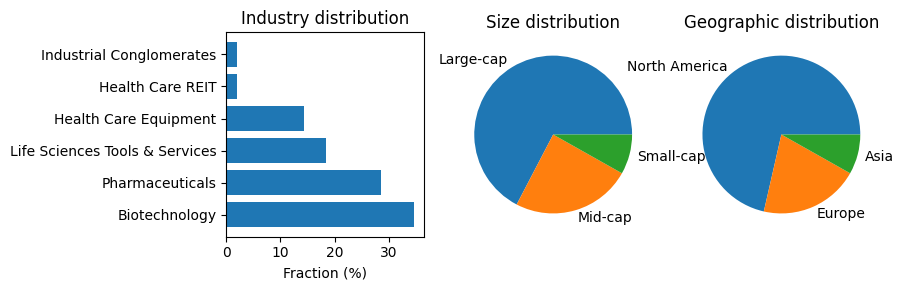

In [2]:
#Load
data=pan.read_csv("Data/Universe.txt",sep=",",engine="python").fillna("NA")#Load data
score=loadScore("Config/Scoring.json")#Load scoring rules
with open("Config/Exrate.json") as f:#Convert all revenue to CHF
    rate=json.load(f)
with open("Config/Convert.json") as f:#Load convertion dictionary
    convert=json.load(f)
    rule=convert["Currency"]
    geography=convert["Market"]
    cost_cat=convert["Cost"]
    ca={float(x):y for x,y in convert["Capital"].items()}

#Convert Universe data
data["Location"]=data["Market"].map(geography)
data["Revenue"]*=data["Market"].map(rule).map(rate)
data["CAGR"]=data["CAGR"]/100
data["NameC"]=data["Ticker"].map(lambda x: x.split(".")[0])

#Convert value for ranking
data=convertForRanking(data,score)
data["Cap"]=data["Revenue"].map(ca)
universe_plot(data,"universe")

# 3. Portfolio Construction
A subset of 16 equities is selected based on thematic scoring.

Selection is performed within each industry group to preserve the overall structure of the investment universe. This ensures diversification while maintaining exposure to the most relevant companies within the theme.

The following figures show the composition of the resulting portfolio.


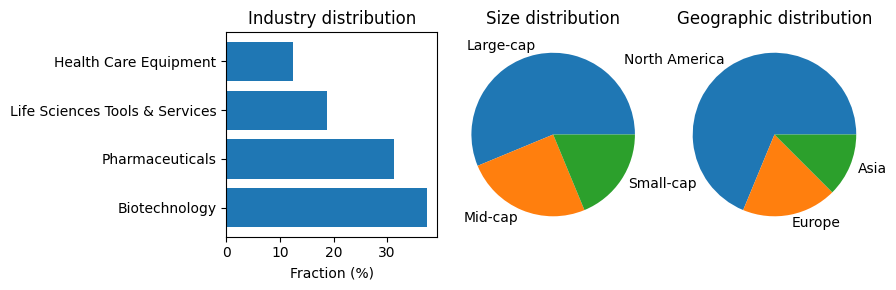

In [3]:
#Number of company to take per industry
nbi=np.floor(data["Industry"].value_counts()/len(data)*18)

#Scoring and sorting
data["Score"]=data.apply(scoreData,axis=1)
data.sort_values(by="Score",ascending=False,inplace=True)
dataf=data[data["Industry"]==nbi.index[0]].head(int(nbi[nbi.index[0]]))
for i in range(1,len(nbi.index)):
    l=data[data["Industry"]==nbi.index[i]].head(int(nbi[nbi.index[i]]))
    dataf=pan.concat([dataf,l],ignore_index=True)
dataf=dataf.reset_index()
universe_plot(dataf,"portfolio")

# 4. Load historical data
- Load ticker data and add information from the universe

In [4]:
#Load data and calculate returns
(dataClose, dataDiv,dataCur, info)=loadAll()
dataClose=dataClose.iloc[:-2]
ret=returns(dataClose)
retEq=ret.drop(columns=["SP500","MSCI-World","MSCI-ACWI"])#Remove brenchmarks

#Correct order of equity between score and ticker data
nameScore=list(dataf["Ticker"].map(lambda w: w.split(".")[0]))
nameClose=list(retEq.columns)
pos={value: idx for idx, value in enumerate(nameScore)}
ind=[pos[x] for x in nameClose]
sc=list(dataf["Score"])
sc=[sc[x] for x in ind]
cap=list(dataf["Revenue"])
cap=[cap[x] for x in ind]
industr=list(dataf["Industry"])
industr=[industr[x] for x in ind]

# 5. Optimization
Portfolio weights are determined using a Bayesian maximum-entropy framework.

The objective is to improve expected return and thematic exposure while limiting unnecessary changes in portfolio allocation. The optimisation starts from prior weights and applies a penalty to deviations, resulting in lower turnover and more stable positioning.

The optimisation is solved under explicit constraints to ensure diversification and risk control.

The objective function combines two components:

- A reward term based on expected return and thematic score  
- An entropy penalty based on the Kullback-Leibler (KL) divergence from prior weights  

The optimisation problem can be expressed as:

$ \Delta G = \chi^2  − \Theta \Delta S$

where:
- $\chi^2$ represents the reward function (return and thematic score)  
- $\Delta S$ represents the entropy penalty  
- $\Theta$ controls the trade-off between performance and stability  

Return and thematic score are normalised by their respective uncertainties. Return uncertainty is estimated using rolling volatility, while thematic score uncertainty is estimated through perturbation and bootstrapping.

The optimisation is performed using Sequential Least Squares Programming (SLSQP), allowing the inclusion of bounds and constraints.

This formulation allows the portfolio to adapt to changing market conditions while avoiding excessive reallocation, which is critical for implementable thematic strategies.

## 5.1 Parameters and constraints definition
The portfolio is subject to the following constraints:
- Position size: 4% – 8%  
- Industry exposure capped relative to universe  
- Annualised volatility: < 20%  
- 1-month 97.5% Value-at-Risk: < 6%  
These constraints are designed to limit concentration and maintain an institutionally consistent risk profile.

In [5]:
#Parameters for optimization
nb=len(retEq.columns)
w0=np.ones(nb)/nb#Initial weight
indus=matrix_correspondance(retEq,data,"Industry")#Correspondance matrix for industry
loca=matrix_correspondance(retEq,data,"Location")#Correspondance matrix for location
capi=matrix_correspondance(retEq,data,"Cap")#Correspondance matrix for location

#Define constraint for optimization
lim={
    "Industry":{"fun":industry_constraint,"lim":(w0@indus)*1.2},
    "VaR":{"fun":var_constraint,"lim":0.06},
    "Volatility":{"fun":vol_constraint,"lim":0.2},
}

bounds=[(0.04,0.08) for x in range(nb)]#Boundaries for each position
maxsc=maxScore(sc,bounds[0])#Maximum Thematic score
var=calc_error(retEq,data)#Calculate errorsre 
param=np.arange(0.5,50,0.5)#Temperature ramp
retEq_np=np.array(retEq)#Make return into array to speed up optimization

## 5.2 Optimization

In [6]:
#Variable definition to speed up the process
it=int(np.floor(len(retEq)/4-1))
w=np.zeros(len(w0))
wd=np.zeros((it,4,len(w0)))
stat=np.zeros((it,4))
msg=np.full((it,3),"",dtype=str)
idx=np.zeros((it+1,len(w0)))
ww0=drift_weight(retEq_np[0:4],w0)

if  False:#To turn on or off the optimization
  w,stat[0],msg[0],idx[0]=optimize_portfolio_Bayes(param,sc,retEq_np[0:8],maxsc,bounds,def_constraints(retEq_np[0:8],lim),ww0[0],var)#Initial optimization
  for index,i in enumerate(range(12,len(retEq),4)):#Optimization
      wd[index]=drift_weight(retEq_np[i-4:i],w)#Drift previous weights
      w,stat[index+1],msg[index+1],idx[index+1]=optimize_portfolio_Bayes(param,sc,retEq_np[i-8:i],maxsc,bounds,def_constraints(retEq_np[i-8:i],lim),wd[index,-1],var)
  np.savez("Results/Opti.npz",w=wd,stat=stat,msg=msg,idx=idx)#Save as optimization is long

# 6. Results

## 6.1 Turnover Analysis
The portfolio is rebalanced using an entropy-based optimisation framework, which penalises large deviations from prior weights.

This results in limited turnover over time and reduces transaction costs. The comparison between gross and net returns indicates that implementation costs have a limited impact on overall performance.

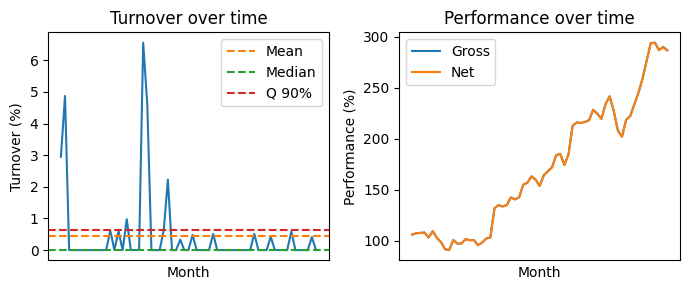

In [7]:
#Reload optimization
opti=np.load("Results/Opti.npz")
cost=opti["idx"][1:-1]

#Make continuous weight table
ww=np.zeros((len(w0),252))
for i in range(len(w0)):
    ww[i]=opti["w"][:-1,:,i].flatten()
ww=ww.transpose()

#Add info about companies from the Universe
da=pan.DataFrame(ww.mean(axis=0),columns=["w0"],index=retEq.columns)
da["Industry"]=da.index.map(lambda x: data[data["NameC"]==x].iloc[0].loc["Industry"])
da["Location"]=da.index.map(lambda x: data[data["NameC"]==x].iloc[0].loc["Location"])
da["Cap"]=da.index.map(lambda x: data[data["NameC"]==x].iloc[0].loc["Cap"])
da["Cost"]=da["Cap"].map(cost_cat)/10000

#Calculate performances
turn,co=calc_turnover(cost,da)
performance=pan.DataFrame(turn,columns=["Turnover"])
performance["Cost"]=co#Calculate rebalancing cost
dataPos=dataClose.drop(columns=["SP500","MSCI-World","MSCI-ACWI"])
return_month=returns(dataPos[0::4])[1:-1]
performance["Return"]=np.array((return_month*ww[0::4]).sum(axis=1))
performance["Return net"]=performance["Return"]-performance["Cost"]
performance["Cum Return"]=(1+performance["Return"]).cumprod()
performance["Cum Return net"]=(1+performance["Return net"]).cumprod()
n_months=len(performance)
n_year=n_months/12
cagr_gross=(performance["Cum Return"].iloc[-1])**(1/n_year)-1
cagr_net=(performance["Cum Return net"].iloc[-1])**(1/n_year)-1
cost_annual=cagr_gross-cagr_net
turnover_plot(performance)

## 6.2 Exposure Analysis
Portfolio exposure is analysed across industries, geographies and market capitalisation.

Industry exposures remain stable due to the imposed constraints. Geographic and size exposures also exhibit limited variation despite not being explicitly constrained, highlighting the stabilising effect of the optimisation framework.

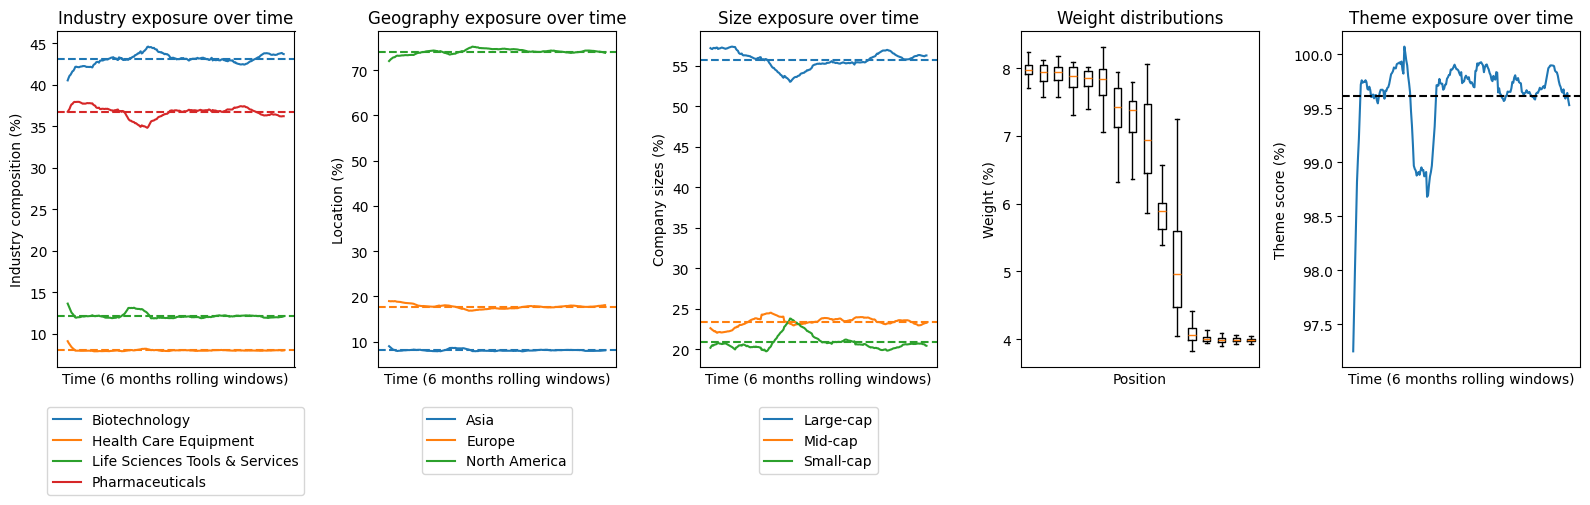

In [8]:
#Calculate exposure
exp_ind=pan.DataFrame(ww @ indus,columns=np.unique(dataf["Industry"]))
exp_loca=pan.DataFrame(ww @ loca,columns=np.unique(dataf["Location"]))
exp_cap=pan.DataFrame(ww @ capi,columns=np.unique(dataf["Cap"]))
exp_w=pan.DataFrame(ww).rolling(24).mean().dropna()
exp_w=exp_w[exp_w.median().sort_values(ascending=False).index]
exp_theme=pan.Series(np.dot(ww,sc)/maxsc)
exposure_plot(exp_ind,exp_loca,exp_cap,exp_w,exp_theme)

## 6.3 Concentration Analysis
Concentration metrics are used to assess the degree of diversification of the portfolio.

The Herfindahl-Hirschman Index and concentration ratios indicate that the portfolio remains well diversified over time. Position limits and industry constraints effectively prevent excessive concentration in individual holdings.

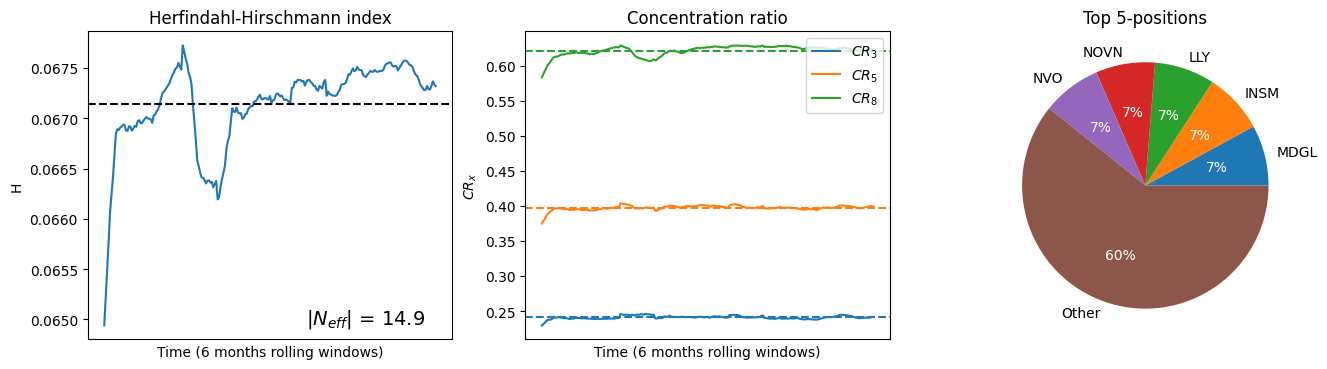

In [9]:
#Concentration metrics
wr=pan.DataFrame(ww)
wr=np.array(wr.rolling(24).mean().dropna())
hhi=calc_HHI(wr)
cr5=calc_CR(wr,5)
cr8=calc_CR(wr,8)
cr3=calc_CR(wr,3)
concentration_plot(hhi,cr3,cr5,cr8,da)

## 6.3 Risk Analysis
Risk metrics are evaluated using rolling windows and include volatility, drawdown and tail-risk measures.

The portfolio exhibits higher volatility than broad equity indices, consistent with its thematic focus. However, downside risk remains broadly aligned with the defined constraints.

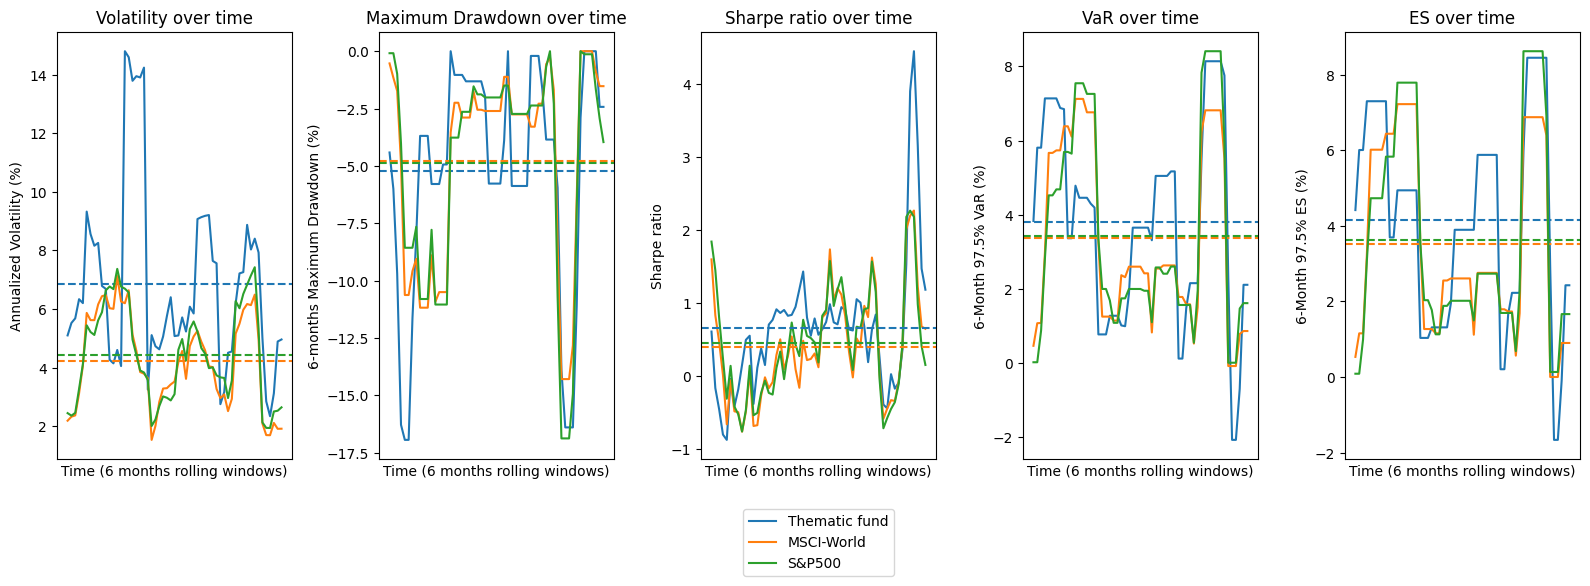

In [14]:
#Risk metrics
b1=dataClose[["SP500","MSCI-World","MSCI-ACWI"]]
b1=returns(b1[0::4])[1:-1]
fund_met=calc_metrics_roll(performance["Return net"],6)
world_met=calc_metrics_roll(b1["MSCI-World"],6)
acwi_met=calc_metrics_roll(b1["MSCI-ACWI"],6)
sp500_met=calc_metrics_roll(b1["SP500"],6)
met=[fund_met,world_met,sp500_met]
risk_plot(met)

## 6.4 Factor Analysis (PCA)
Principal Component Analysis is used to decompose returns into orthogonal factors.

The first component represents general market exposure, while the second captures a theme-specific factor. The portfolio’s exposure to this second component suggests that returns are not solely driven by broad market movements.

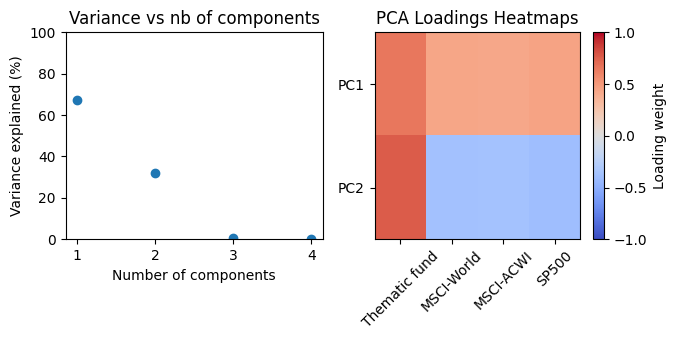

In [16]:
#PCA factor regression
mat=np.array([performance["Return net"],b1["MSCI-World"],b1["MSCI-ACWI"],b1["SP500"]]).transpose()
be=pca_factor(mat,2)
be.to_csv("Results/pca.csv")
be=np.round(be,1)
be.to_html("Results/pca.html")

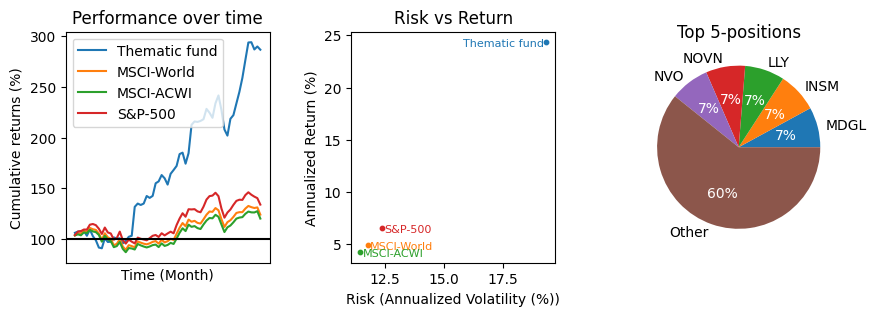

In [15]:
#Performance metric comparison with benchmarks
met2=np.array([calc_metrics(performance["Return net"],freq=12),calc_metrics(b1["MSCI-World"],freq=12),calc_metrics(b1["MSCI-ACWI"],freq=12),calc_metrics(b1["SP500"],freq=12)])
name=["Thematic fund","MSCI-World","MSCI-ACWI","S&P-500"]
perf_plot(performance,b1,["Thematic fund","MSCI-World","MSCI-ACWI","S&P-500"],met2,da)
met3=pan.DataFrame(met2.transpose(),columns=name)
met3.to_csv("Results/metrics.csv")
met3=np.round(met3,1)
met3.to_html("Results/metrics.html")

## 6.5 Interpretation
The portfolio demonstrates strong performance relative to global equity benchmarks, supported by exposure to cardiometabolic innovation.

This is achieved with higher volatility, consistent with a thematic equity strategy. Turnover remains limited, supporting the implementability of the approach, while exposure and concentration analyses confirm a diversified allocation.

Results should be interpreted with caution, as the analysed period benefited from favourable sector dynamics.


## 6.6 Limitations

The analysis relies on historical data and simplified assumptions.

Key limitations include:
- uncertainty in clinical and regulatory outcomes  
- simplified thematic scoring  
- absence of valuation modelling  
- no macroeconomic or currency considerations  

Results should therefore be interpreted as an analytical case study rather than a predictive model.

# 7. Conclusion
This notebook demonstrates how scientific expertise, quantitative modelling and investment reasoning can be combined into a structured thematic investment framework.

It illustrates a process for capturing differentiated thematic exposure while maintaining diversification and risk control, with particular relevance to healthcare and innovation-driven sectors.